# Exercice d’approfondissement

Une étude a été menée auprès d’étudiant.e.s afin de mieux comprendre les facteurs
pouvant être associés à leur réussite scolaire.

Pour chaque étudiant, différentes informations ont été recueillies concernant notamment ses habitudes de travail, son environnement d’étude, son sommeil et son parcours
scolaire. Les résultats obtenus à un examen sont également disponibles. On dispose de deux
indicateurs de réussite :
- pass_status, indiquant si l’étudiant a réussi ou échoué à l’examen ;
- exam_score, correspondant à la note obtenue à l’examen.

Calculez les statistiques descriptives puis faites le traitement statistique adéquat étudier
la réussite, puis le niveau de réussite, des étudiant.e.s.

Les données sont stockées dans le fichier student_performance.csv.

**Questions de recherche :**

1. Existe-t-il des indicateurs corrélés à la réussite et à l'échec des étudiants ?
2. Parmi les étudiants ayant réussi leurs examens, existe-t-il des indicateurs permettant de refléter le degré de leur réussite ?

## 1. Préparation de l’environnement et import des données

### 1.1 Import des bibliothèques d’analyse

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


### 1.2 Lecture des données brutes

Tout d'abord, lire le tableau et afficher les dix premières lignes.

In [37]:
student_exam = pd.read_csv("data/student_exam_performance.csv")
student_exam.head(10)

,student_id,gender,revision_frequency,sleep_quality,exam_score,pass_status
0,STU_000001,Female,Rarely,Excellent,90.40,Pass
1,STU_000002,Male,Daily,Excellent,86.21,Pass
2,STU_000003,Other,Weekly,Poor,76.11,Pass
3,STU_000004,Male,Weekly,Fair,79.74,Pass
4,STU_000005,Female,Rarely,Excellent,50.66,Pass
5,STU_000006,Male,Daily,Fair,67.90,Pass
6,STU_000007,Male,Weekly,Fair,53.86,Pass
7,STU_000008,Female,Weekly,Good,97.61,Pass
8,STU_000009,Male,Weekly,Good,34.44,Fail
9,STU_000010,Female,Weekly,Good,39.05,Fail


### 1.3 Contrôle de la qualité des données : vérification des valeurs manquantes

Avant l’analyse proprement dite, nous vérifions d’abord l’intégrité des données afin d’éviter que les valeurs manquantes ne faussent les résultats de l’analyse.

In [38]:
student_exam.isna().sum()

total_samples = len(student_exam)
missing_num = student_exam["sleep_quality"].isna().sum()
missing_rate = missing_num / total_samples * 100

print(f"total：{total_samples}")
print(f"sleep_quality ：{missing_num}")
print(f"Taux de valeurs manquantes：{missing_rate:.2f}%")

total：100000
sleep_quality ：6994
Taux de valeurs manquantes：6.99%


Ici, nous pouvons constater que la variable sleep_quality présente un très grand nombre de valeurs manquantes ; c’est la seule variable concernée, avec un taux de valeurs manquantes de 6,99 %. Ce taux, inférieur à 10 %, correspond à un taux faible de manquants.

Nous allons maintenant tester si ces manquants sont aléatoires (test MCAR).

In [39]:
student_exam["sleep_is_missing"] = student_exam["sleep_quality"].isna()

# 1. Welch's test student
score_complete = student_exam[~student_exam["sleep_is_missing"]]["exam_score"]
score_missing = student_exam[student_exam["sleep_is_missing"]]["exam_score"]
t_stat, p_score = stats.ttest_ind(score_complete, score_missing, equal_var=False)
print(f"pvalue de scores d’examen entre les deux groupes：{p_score:.4f}")

# 2. test chi2
table_pass = pd.crosstab(student_exam["sleep_is_missing"], student_exam["pass_status"])
chi2_pass, p_pass, _, _ = stats.chi2_contingency(table_pass)
print(f"pvalue de  taux de réussite entre les deux groupes：{p_pass:.4f}")

# 3. test chi2
table_rev = pd.crosstab(student_exam["sleep_is_missing"], student_exam["revision_frequency"])
chi2_rev, p_rev, _, _ = stats.chi2_contingency(table_rev)
print(f"pvalue de  distributions de fréquence de révision entre les deux groupes：{p_rev:.4f}")


pvalue de scores d’examen entre les deux groupes：0.4855
pvalue de  taux de réussite entre les deux groupes：0.5127
pvalue de  distributions de fréquence de révision entre les deux groupes：0.0520


Test du mécanisme des valeurs manquantes : pour les 6994 enregistrements manquants de la variable sleep_quality, nous utilisons le test t de Welch et le test du chi-deux afin de comparer respectivement les scores aux examens, les taux de réussite et les fréquences de révision entre le groupe des données manquantes et le groupe des données complètes. Les résultats montrent que les p-valeurs des trois tests sont supérieures au seuil de signification de 0,05. Il n’existe donc pas de preuve statistique que les manquants soient liés aux autres variables observées ; nous concluons à des manquants complètement aléatoires (MCAR).

Traitement retenu : afin de garantir la fiabilité des tests d’hypothèses ultérieurs, nous optons ici pour la suppression des valeurs manquantes. Après élimination des échantillons pour lesquels la qualité du sommeil est manquante, l’effectif valide finalement inclus dans l’analyse s’élève à 93 006 individus.

In [40]:
student_data = student_exam[ student_exam[["gender","revision_frequency","sleep_quality"]].notna().all(axis=1)].copy()
student_data.isna().sum()

student_id            0
gender                0
revision_frequency    0
sleep_quality         0
exam_score            0
pass_status           0
sleep_is_missing      0
dtype: int64

## 2. Description des variables et statistiques descriptives

### 2.1 Définition des types et des rôles des variables

Tableau

表格

| Type de variable | Nom de la variable | Signification | Type de données |
| --- | --- | --- | --- |
| Variable explicative (indicateur d’influence) | `gender` | Genre de l’étudiant | Variable catégorielle à trois modalités (Female/Male/Other) |
| Variable explicative (indicateur d’influence) | `revision_frequency` | Fréquence de révision | Variable catégorielle ordinale (Rarely/Weekly/Daily) |
| Variable explicative (indicateur d’influence) | `sleep_quality` | Qualité du sommeil | Variable catégorielle ordinale (Poor/Fair/Good/Excellent) |
| Variable de résultat (question 1) | `pass_status` | Réussite ou échec à l’examen | Variable binaire (Pass/Fail) |
| Variable de résultat (question 2) | `exam_score` | Note à l’examen | Variable numérique continue (0 à 100) |

### 2.2 Distribution générale de l’échantillon

#### 2.2.1 Effectifs et proportions des variables catégorielles

In [41]:
for col in ["gender", "revision_frequency", "sleep_quality", "pass_status"]:
    print(f"========== {col} ==========")
    dist_df = student_data[col].value_counts().reset_index()
    dist_df.columns = ["modalité", "count"]
    dist_df["taux(%)"] = (dist_df["count"] / len(student_data) * 100).round(2)
    print(dist_df)
    print()

========== gender ==========
  modalité  count  taux(%)
0     Male  45693    49.13
1   Female  45411    48.83
2    Other   1902     2.05

========== revision_frequency ==========
  modalité  count  taux(%)
0   Weekly  46286    49.77
1    Daily  28089    30.20
2   Rarely  18631    20.03

========== sleep_quality ==========
    modalité  count  taux(%)
0       Fair  32439    34.88
1       Good  32380    34.81
2  Excellent  14134    15.20
3       Poor  14053    15.11

========== pass_status ==========
  modalité  count  taux(%)
0     Pass  71999    77.41
1     Fail  21007    22.59



#### 2.2.2 Statistiques globales des notes à l’examen

In [42]:
score_overall = student_data["exam_score"].describe().round(2)
print("Stat. descriptives des notes, échantillon total：")
print(score_overall)

Stat. descriptives des notes, échantillon total：
count    93006.00
mean        61.94
std         15.85
min          0.00
25%         51.25
50%         61.96
75%         72.70
max        100.00
Name: exam_score, dtype: float64


### 2.3 Descriptions croisées : comparaison visuelle entre les indicateurs et le résultat de l’examen

Nous commençons par des statistiques croisées et des graphiques pour observer visuellement les différences de taux de réussite et de notes selon les groupes, afin de préparer les tests d’hypothèses ultérieurs.

#### 2.3.1 Comparaison des taux de réussite selon les groupes

Taux de réussite (%) selon gender :
gender
Female    77.38
Male      77.50
Other     76.13
Name: pass_status, dtype: float64

Taux de réussite (%) selon revision_frequency :
revision_frequency
Daily     77.82
Rarely    77.40
Weekly    77.17
Name: pass_status, dtype: float64

Taux de réussite (%) selon sleep_quality :
sleep_quality
Excellent    77.24
Fair         77.36
Good         77.44
Poor         77.64
Name: pass_status, dtype: float64



C:\Users\zhoumengzhe\AppData\Local\Temp\ipykernel_5212\2027780842.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\zhoumengzhe\AppData\Local\Temp\ipykernel_5212\2027780842.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\zhoumengzhe\AppData\Local\Temp\ipykernel_5212\2027780842.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


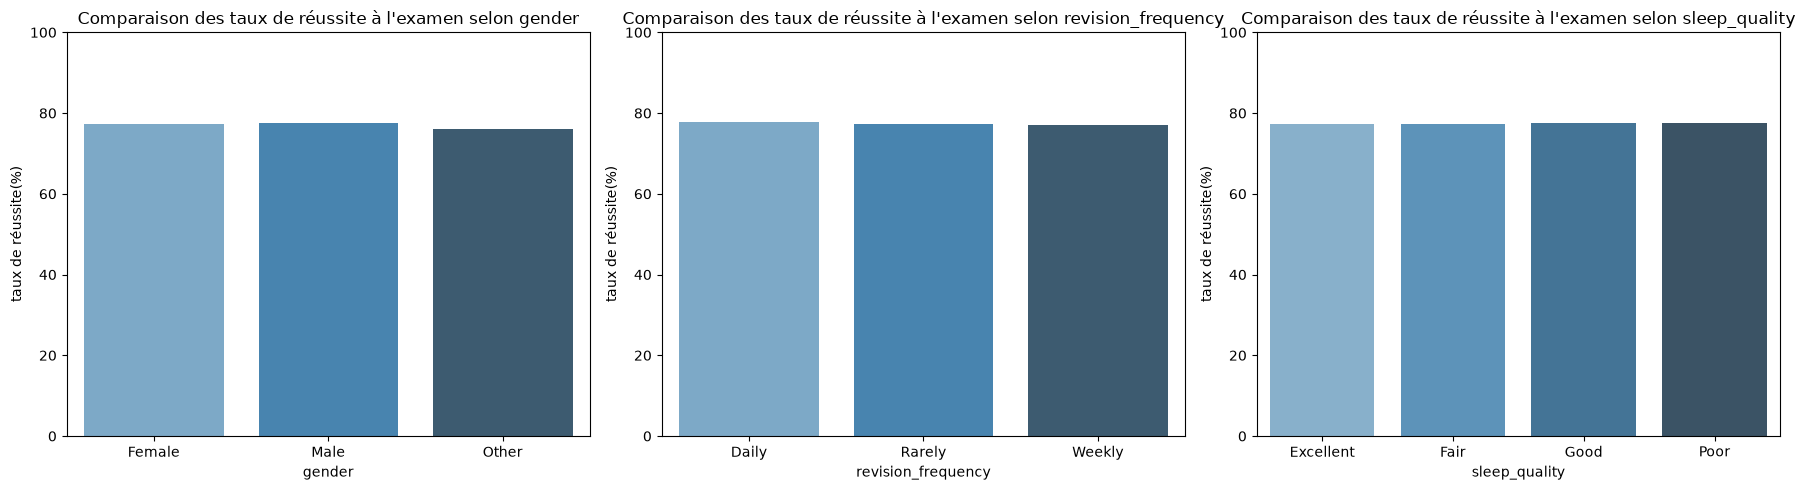

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, factor in enumerate(["gender", "revision_frequency", "sleep_quality"]):
    pass_rate = student_data.groupby(factor)["pass_status"].apply(
        lambda x: (x == "Pass").mean() * 100
    ).round(2)
    print(f"Taux de réussite (%) selon {factor} :")
    print(pass_rate)
    print()

    sns.barplot(
        x=pass_rate.index,
        y=pass_rate.values,
        ax=axes[idx],
        palette="Blues_d"
    )
    axes[idx].set_title(f"Comparaison des taux de réussite à l'examen selon {factor}", fontsize=12)
    axes[idx].set_ylabel("taux de réussite(%)")
    axes[idx].set_ylim(0, 100)

plt.tight_layout()
plt.show()


#### 2.3.2 Distribution des notes parmi les étudiants reçus, selon les groupes

C:\Users\zhoumengzhe\AppData\Local\Temp\ipykernel_5212\3811880536.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\zhoumengzhe\AppData\Local\Temp\ipykernel_5212\3811880536.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\zhoumengzhe\AppData\Local\Temp\ipykernel_5212\3811880536.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


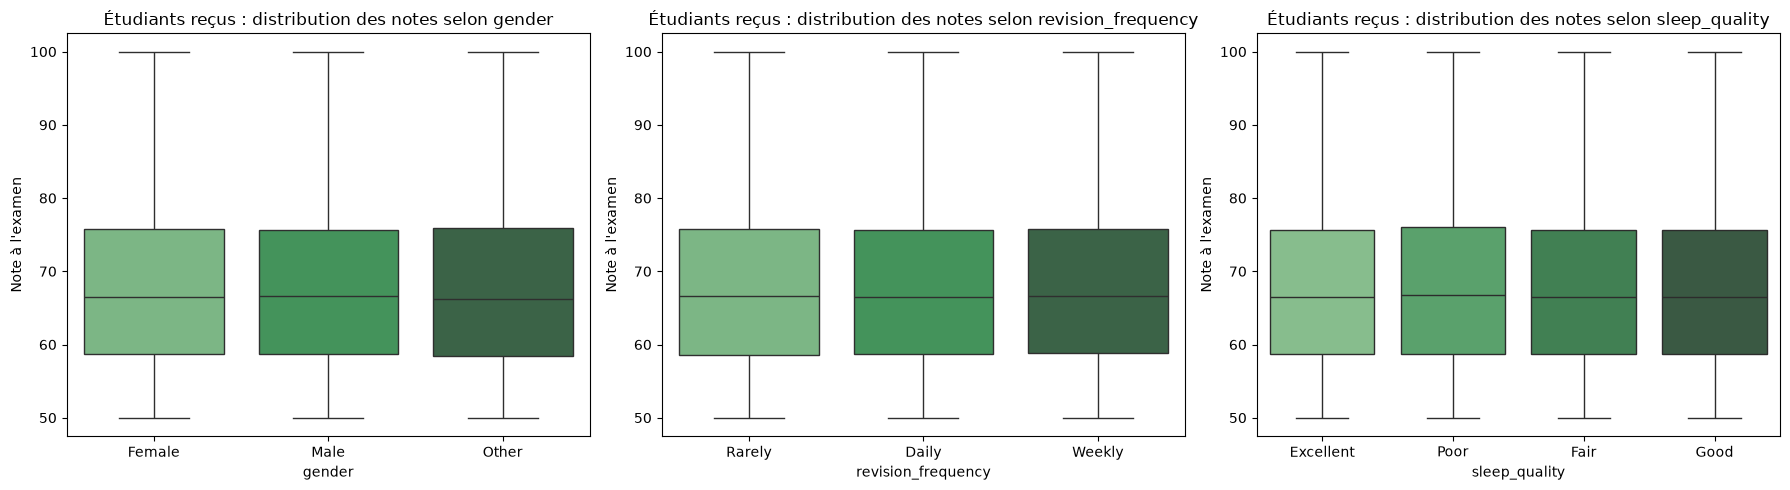

In [44]:
pass_students = student_data[student_data["pass_status"] == "Pass"].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, factor in enumerate(["gender", "revision_frequency", "sleep_quality"]):
    sns.boxplot(
        data=pass_students,
        x=factor,
        y="exam_score",
        ax=axes[idx],
        palette="Greens_d"
    )
    axes[idx].set_title(f"Étudiants reçus : distribution des notes selon {factor}", fontsize=12)
    axes[idx].set_ylabel("Note à l'examen")

plt.tight_layout()
plt.show()


Conclusion descriptive : à partir des données et des graphiques, nous observons d’abord que les différences de fréquence de révision, de qualité du sommeil et de genre ne s’accompagnent pas de différences manifestes de taux de réussite ni de notes. Nous utiliserons ensuite des tests d’hypothèses pour vérifier si ces écarts sont statistiquement significatifs.

## 3. Question 1 : Analyse des indicateurs associés à la réussite / l’échec à l’examen

### 3.1 Présentation de la méthode d’analyse

Pour cette question, la variable de résultat `pass_status` est une variable binaire, et toutes les variables explicatives sont également catégorielles. Nous utilisons donc le **test du chi-deux d’indépendance** pour les vérifications :

- Hypothèse nulle H₀ : le facteur étudié est indépendant de la réussite à l’examen (le facteur n’a pas de lien avec le taux de réussite)
- Hypothèse alternative H₁ : le facteur étudié n’est pas indépendant de la réussite à l’examen (le facteur est significativement associé au taux de réussite)

Nous fixons le seuil de signification α = 0,05 : si la p-valeur du test est inférieure à 0,05, nous rejetons l’hypothèse nulle et concluons à une association significative entre ce facteur et la réussite ou l’échec à l’examen.

### 3.2 Test du chi-deux pour chaque indicateur séparément

In [45]:
def chi_square_analysis(data, factor_col, target="pass_status", alpha=0.05):
    contingency = pd.crosstab(data[factor_col], data[target])

    chi2_stat, p_value, dof, expected = stats.chi2_contingency(contingency)
    
    print(f"===== Indicateur testé : {factor_col} =====")
    print(f"Statistique du chi-deux = {chi2_stat:.4f}")
    print(f"Degrés de liberté = {dof}")
    print(f"p-valeur = {p_value:.4e}")
    
    if p_value < alpha:
        print(f"Conclusion du test : p < {alpha}, rejet de l'hypothèse nulle")
        print(f"Cet indicateur présente une association statistiquement significative avec la réussite ou l'échec à l'examen\n")
    else:
        print(f"Conclusion du test : p ≥ {alpha}, on ne rejette pas l'hypothèse nulle")
        print(f"Il n'y a pas suffisamment de preuves pour affirmer que cet indicateur est lié au taux de réussite\n")
    
    return chi2_stat, p_value


# Test successif des trois facteurs d'influence
for factor in ["gender", "revision_frequency", "sleep_quality"]:
    chi_square_analysis(student_data, factor)


===== Indicateur testé : gender =====
Statistique du chi-deux = 2.0015
Degrés de liberté = 2
p-valeur = 3.6761e-01
Conclusion du test : p ≥ 0.05, on ne rejette pas l'hypothèse nulle
Il n'y a pas suffisamment de preuves pour affirmer que cet indicateur est lié au taux de réussite

===== Indicateur testé : revision_frequency =====
Statistique du chi-deux = 4.3038
Degrés de liberté = 2
p-valeur = 1.1626e-01
Conclusion du test : p ≥ 0.05, on ne rejette pas l'hypothèse nulle
Il n'y a pas suffisamment de preuves pour affirmer que cet indicateur est lié au taux de réussite

===== Indicateur testé : sleep_quality =====
Statistique du chi-deux = 0.7231
Degrés de liberté = 3
p-valeur = 8.6777e-01
Conclusion du test : p ≥ 0.05, on ne rejette pas l'hypothèse nulle
Il n'y a pas suffisamment de preuves pour affirmer que cet indicateur est lié au taux de réussite



**Conclusion pour la question 1 :**

Nous avons étudié l’association entre le statut de réussite à l’examen et trois indicateurs (genre, fréquence de révision et qualité du sommeil) à l’aide du test du chi-deux d’indépendance. Les résultats indiquent qu’au seuil de signification α = 0,05, les p-valeurs des trois indicateurs sont toutes supérieures au seuil critique : genre (p = 0,368), fréquence de révision (p = 0,116), qualité du sommeil (p = 0,868).

Par conséquent, cette étude ne met pas en évidence de preuves statistiques suffisantes pour affirmer que ces trois indicateurs sont significativement associés à la réussite ou à l’échec des étudiants à l’examen. Les données disponibles ne permettent pas de soutenir l’hypothèse selon laquelle la fréquence de révision et la qualité du sommeil influencent le taux de réussite à l’examen.

## 4. Question 2 : Analyse des indicateurs influençant le niveau des notes parmi les étudiants reçus

### 4.1 Présentation de la méthode d’analyse

Cette partie ne concerne que le groupe des étudiants ayant réussi l’examen. La variable de résultat `exam_score` est une variable numérique continue, tandis que les variables explicatives sont des variables catégorielles à plusieurs modalités. Nous utilisons donc l’**analyse de variance à un facteur (One-way ANOVA)** pour effectuer les vérifications :

- Hypothèse nulle H₀ : les moyennes des notes sont identiques pour tous les groupes définis par cet indicateur (l’indicateur n’a pas d’effet sur les notes)
- Hypothèse alternative H₁ : au moins un groupe présente une moyenne de notes différente des autres

Si le test ANOVA est significatif (p < 0,05), nous réalisons ensuite des **comparaisons multiples post-hoc de Tukey** afin d’identifier précisément quelles paires de groupes présentent une différence significative de notes.

> 
> Remarque préalable : l’effectif des étudiants reçus dépasse 7 000. D’après le théorème central limite, la distribution d’échantillonnage des moyennes est approximativement normale. L’ANOVA est robuste face à de légers écarts à la normalité ; nous nous concentrons donc sur la vérification de l’homogénéité des variances.

### 4.2 Test d’homogénéité des variances (test de Levene)

In [46]:
def levene_analysis(data, factor_col, value="exam_score", alpha=0.05):
    groups = [data[data[factor_col] == g][value] for g in data[factor_col].unique()]
    stat, p_value = stats.levene(*groups)
    
    print(f"===== Test d'homogénéité des variances pour l'indicateur : {factor_col} =====")
    print(f"Statistique = {stat:.4f}")
    print(f"p-valeur = {p_value:.4e}")
    
    if p_value < alpha:
        print(f"Conclusion : p < {alpha}, les variances des groupes ne sont pas homogènes\n")
    else:
        print(f"Conclusion : p ≥ {alpha}, l'homogénéité des variances est respectée\n")
    return p_value


# Test d'homogénéité des variances pour les trois indicateurs
for factor in ["gender", "revision_frequency", "sleep_quality"]:
    levene_analysis(pass_students, factor)


===== Test d'homogénéité des variances pour l'indicateur : gender =====
Statistique = 0.4600
p-valeur = 6.3131e-01
Conclusion : p ≥ 0.05, l'homogénéité des variances est respectée

===== Test d'homogénéité des variances pour l'indicateur : revision_frequency =====
Statistique = 0.8896
p-valeur = 4.1082e-01
Conclusion : p ≥ 0.05, l'homogénéité des variances est respectée

===== Test d'homogénéité des variances pour l'indicateur : sleep_quality =====
Statistique = 0.5628
p-valeur = 6.3951e-01
Conclusion : p ≥ 0.05, l'homogénéité des variances est respectée



**Test d’homogénéité des variances**

Afin de vérifier les conditions d’application de l’analyse de variance à un facteur, nous réalisons le test de Levene pour examiner l’homogénéité des variances intergroupes des trois indicateurs, avec un seuil de signification fixé à α = 0,05.

Les résultats des tests montrent qu’il n’existe pas de différence statistiquement significative des variances intergroupes pour le genre (p = 0,631), la fréquence de révision (p = 0,411) et la qualité du sommeil (p = 0,640) ; l’hypothèse d’homogénéité des variances est donc respectée pour les trois variables. Compte tenu du théorème central limite pour les grands échantillons, les conditions d’application de l’ANOVA classique à un facteur sont satisfaites.

### 4.3 Analyse de variance à un facteur

Si l’homogénéité des variances est vérifiée, nous utilisons l’ANOVA classique ; dans le cas contraire, nous complétons par le test non paramétrique de Kruskal-Wallis comme vérification de robustesse.

In [47]:
def anova_analysis(data, factor_col, value="exam_score", alpha=0.05, equal_var=True):
    groups = [data[data[factor_col] == g][value] for g in data[factor_col].unique()]
    
    if equal_var:
        stat, p_value = stats.f_oneway(*groups)
        test_name = "Analyse de variance à un facteur (ANOVA)"
    else:
        stat, p_value = stats.kruskal(*groups)
        test_name = "Test non paramétrique de Kruskal-Wallis"
    
    print(f"===== Indicateur : {factor_col} — {test_name} =====")
    print(f"Statistique = {stat:.4f}")
    print(f"p-valeur = {p_value:.4e}")
    
    if p_value < alpha:
        print(f"Conclusion : p < {alpha}, rejet de l'hypothèse nulle")
        print(f"Cet indicateur a un effet significatif sur les notes des étudiants reçus\n")
    else:
        print(f"Conclusion : p ≥ {alpha}, on ne rejette pas l'hypothèse nulle")
        print(f"Il n'y a pas suffisamment de preuves pour affirmer que cet indicateur influe sur le niveau des notes\n")
    return p_value


for factor in ["gender", "revision_frequency", "sleep_quality"]:
    anova_analysis(pass_students, factor, equal_var=True)


===== Indicateur : gender — Analyse de variance à un facteur (ANOVA) =====
Statistique = 0.0696
p-valeur = 9.3272e-01
Conclusion : p ≥ 0.05, on ne rejette pas l'hypothèse nulle
Il n'y a pas suffisamment de preuves pour affirmer que cet indicateur influe sur le niveau des notes

===== Indicateur : revision_frequency — Analyse de variance à un facteur (ANOVA) =====
Statistique = 1.0468
p-valeur = 3.5107e-01
Conclusion : p ≥ 0.05, on ne rejette pas l'hypothèse nulle
Il n'y a pas suffisamment de preuves pour affirmer que cet indicateur influe sur le niveau des notes

===== Indicateur : sleep_quality — Analyse de variance à un facteur (ANOVA) =====
Statistique = 0.6792
p-valeur = 5.6463e-01
Conclusion : p ≥ 0.05, on ne rejette pas l'hypothèse nulle
Il n'y a pas suffisamment de preuves pour affirmer que cet indicateur influe sur le niveau des notes



**Résultats de l’analyse de variance à un facteur**

Sur l’échantillon des étudiants reçus, et après vérification de l’homogénéité des variances par le test de Levene, nous mettons en œuvre l’ANOVA classique à un facteur pour tester successivement l’effet du genre, de la fréquence de révision et de la qualité du sommeil sur les notes à l’examen, avec un seuil de signification fixé à α = 0,05.

Les résultats indiquent que les p-valeurs des trois indicateurs sont toutes supérieures au seuil critique de 0,05 : genre (F = 0,070, p = 0,933), fréquence de révision (F = 1,047, p = 0,351), qualité du sommeil (F = 0,679, p = 0,565).

Par conséquent, cette étude ne dispose pas de preuves statistiques suffisantes pour affirmer que ces trois indicateurs influencent significativement le niveau des notes au sein du groupe des étudiants reçus ; il n’est donc pas nécessaire de réaliser des comparaisons multiples post‑hoc.

## 5. Bilan et conclusions de l’étude

### 5.1 Présentation générale de l’étude

Cette étude porte sur les facteurs influençant les performances scolaires des étudiants. À partir d’un jeu de données sur les résultats aux examens, nous réalisons une analyse statistique systématique pour répondre à deux questions de recherche principales :

1. Existe-t-il des indicateurs liés à la réussite ou à l’échec des étudiants à l’examen ;
2. Parmi les étudiants ayant réussi l’examen, existe-t-il des indicateurs influençant le niveau de leurs notes.

Trois variables explicatives sont retenues : **le genre, la fréquence de révision et la qualité du sommeil**. Les variables de résultat sont le statut de réussite à l’examen et la note obtenue. Nous procédons successivement au test du mécanisme des valeurs manquantes, aux statistiques descriptives, au test du chi-deux d’indépendance, au test d’homogénéité des variances et à l’analyse de variance à un facteur. Le seuil de signification de l’ensemble des tests est fixé à α = 0,05.

Avant l’analyse, les valeurs manquantes de la variable qualité du sommeil ont été diagnostiquées : elles sont considérées comme manquantes complètement aléatoires. Après suppression des observations concernées, l’effectif valide inclus dans l’analyse s’élève à 93 006 individus.

### 5.2 Principaux résultats de l’étude

#### (I) Question 1 : test des indicateurs associés à la réussite ou à l’échec

Le test du chi-deux d’indépendance est utilisé pour étudier l’association entre les variables explicatives catégorielles et la variable de résultat binaire. Les résultats sont les suivants :

- **Genre** : statistique du chi-deux = 2,0015, degrés de liberté = 2, p = 0,368. Il n’existe pas de différence statistiquement significative des taux de réussite selon le genre.
- **Fréquence de révision** : statistique du chi-deux = 4,3038, degrés de liberté = 2, p = 0,116. Il n’existe pas de différence statistiquement significative des taux de réussite selon la fréquence de révision.
- **Qualité du sommeil** : statistique du chi-deux = 0,7231, degrés de liberté = 3, p = 0,868. Il n’existe pas de différence statistiquement significative des taux de réussite selon la qualité du sommeil.

**Conclusion** : dans le cadre des indicateurs et de l’échantillon de cette étude, nous ne disposons pas de preuves statistiques suffisantes pour affirmer que le genre, la fréquence de révision et la qualité du sommeil sont significativement associés à la réussite ou à l’échec à l’examen.

#### (II) Question 2 : test des indicateurs influençant les notes des étudiants reçus

Sur le sous-échantillon des étudiants reçus, le test de Levene confirme l’homogénéité des variances pour les trois indicateurs. Nous mettons ensuite en œuvre l’ANOVA classique à un facteur afin d’examiner les différences de moyennes des notes entre groupes :

- **Genre** : statistique F = 0,0696, p = 0,933. La moyenne des notes ne diffère pas de manière statistiquement significative entre les étudiants reçus de genres différents.
- **Fréquence de révision** : statistique F = 1,0468, p = 0,351. La moyenne des notes ne diffère pas de manière statistiquement significative selon la fréquence de révision des étudiants reçus.
- **Qualité du sommeil** : statistique F = 0,6792, p = 0,565. La moyenne des notes ne diffère pas de manière statistiquement significative selon la qualité du sommeil des étudiants reçus.

Aucun des résultats de l’analyse de variance n’est significatif ; il n’est donc pas nécessaire de réaliser des comparaisons multiples post-hoc de Tukey.

**Conclusion** : parmi les étudiants reçus, nous ne trouvons pas de preuves statistiques suffisantes pour soutenir l’idée que le genre, la fréquence de révision et la qualité du sommeil influencent significativement le niveau des notes.

### 5.3 Discussion : interprétation de l’« absence d’association significative »

Les résultats de cette étude contredisent l’intuition courante selon laquelle réviser et bien dormir améliorent les résultats scolaires. Ce constat ne vient pas d’une erreur méthodologique, mais peut s’expliquer par des raisons statistiques et liées au protocole de recherche :

1. **Effet de restriction de l’échantillon tronqué**
L’analyse sur les étudiants reçus repose sur un échantillon tronqué : tous les individus dont la note est inférieure au seuil de réussite sont exclus. Parmi les étudiants qui révisent peu ou dont la qualité du sommeil est mauvaise, ceux aux résultats les plus faibles ont déjà été écartés. Les caractéristiques comportementales et la distribution des notes du sous-échantillon restant sont confinées dans l’intervalle des notes de réussite, ce qui réduit fortement le pouvoir explicatif des variables.
2. **Granularité grossière des mesures**
Les principales variables explicatives sont des variables catégorielles ordinales peu fines, fondées en grande partie sur une auto-évaluation subjective. Deux étudiants appartenant à la même modalité « révision quotidienne » peuvent présenter de grandes disparités en termes de durée effective de révision et d’efficacité de l’apprentissage. Cette hétérogénéité intra-groupe augmente la variance interne et atténue les différences inter-groupes. Par ailleurs, l’évaluation subjective de la qualité du sommeil est mal délimitée et comporte une erreur de mesure importante, ce qui affaiblit davantage l’association réelle entre cette variable et la note à l’examen.
3. **Complexité multifactorielle des performances scolaires**
Le résultat à un examen résulte de l’interaction de nombreux facteurs : connaissances préalables, méthode de travail, difficulté du cours, état au moment de l’épreuve, etc. Cette étude ne retient que trois indicateurs comportementaux ; l’effet propre de chaque facteur est donc faible, et n’atteint pas le seuil de signification statistique même avec un grand échantillon.

### 5.4 Limites de l’étude

1. **Limite liée aux variables** : seulement trois variables explicatives sont intégrées. Il manque des indicateurs plus informatifs, tels que le niveau initial, la durée réelle de travail ou l’environnement familial ; il est donc impossible de décrire complètement les mécanismes qui déterminent les résultats aux examens.
2. **Limite liée à la mesure** : les variables explicatives principales sont des catégories grossières et des auto-évaluations subjectives. Le manque de précision des mesures peut masquer les associations réelles entre variables.
3. **Limite de l’inférence causale** : il s’agit d’une étude observationnelle transversale. Elle ne permet que de mettre en évidence des associations, pas d’établir un lien de causalité. Les conclusions ne valent que pour l’échantillon étudié ; leur généralisation à d’autres populations d’étudiants doit être prudente.